# Transformation process

Shows how one case changes at every step of the data pipeline, from the raw `NIfTI` files to training patches.

1. Preprocessing: `preprocess_transforms()` (what `scripts/preprocess.py` saves to `data/processed`)
2. Evaluation pipeline: label conversion into regions ET / TC / WT / RC
3. Training pipeline: random patches and augmentation

Run from anywhere inside the repo. The first cell adds the repo root to `sys.path`.

In [1]:
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "src").is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from src.dataset.manifest import MODALITIES, build_manifest
from src.dataset.transforms import REGIONS, preprocess_transforms, eval_transforms, train_transforms


print("Repo root:", REPO_ROOT)

Repo root: /home/student2/projects/BraTS2024


## 1. Pick a case

In [2]:
SEED = 23  # change to look at another case

manifest = build_manifest()
record = random.Random(SEED).choice(manifest)

### Case info

In [3]:
print(f"{len(manifest)} cases in manifest\n")

info = {
    "case_id": record["case_id"],
    "patient_id": record["patient_id"],
    "source": record["source"],
}

files = {m: Path(p).name for m, p in zip(MODALITIES, record["image"])}
files["label"] = Path(record["label"]).name


for key, value in info.items():
    print(f"{key:<11}: {value}")
    
print()

for key, value in files.items():
    print(f"{key:<11}: {value}")

1621 cases in manifest

case_id    : BraTS-GLI-02624-100
patient_id : 02624
source     : training_data_additional

t1n        : BraTS-GLI-02624-100-t1n.nii.gz
t1c        : BraTS-GLI-02624-100-t1c.nii.gz
t2w        : BraTS-GLI-02624-100-t2w.nii.gz
t2f        : BraTS-GLI-02624-100-t2f.nii.gz
label      : BraTS-GLI-02624-100-seg.nii.gz


## 1.1 Original data

,shape,dtype,voxel size (mm),orientation,min,max
file,,,,,,
t1n,"(182, 218, 182)",float32,"(1.0, 1.0, 1.0)",LAS,0.0,1362.835815
t1c,"(182, 218, 182)",float32,"(1.0, 1.0, 1.0)",LAS,0.0,1452.866211
t2w,"(182, 218, 182)",float32,"(1.0, 1.0, 1.0)",LAS,0.0,1373.986084
t2f,"(182, 218, 182)",float32,"(1.0, 1.0, 1.0)",LAS,0.0,752.950500
label,"(182, 218, 182)",float64,"(1.0, 1.0, 1.0)",LAS,0.0,4.000000


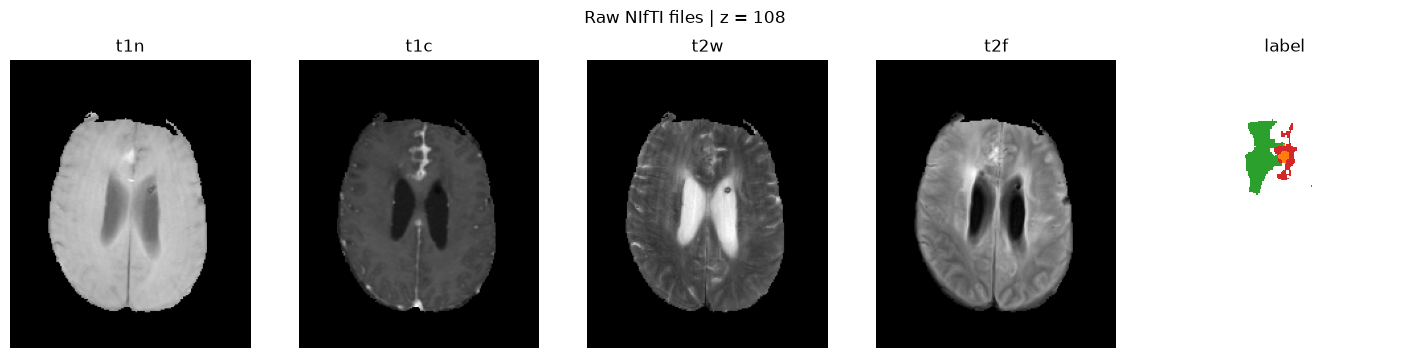

In [4]:
import nibabel as nib

LABEL_NAMES = {1: "NETC", 2: "SNFH", 3: "ET", 4: "RC"}
LABEL_CMAP = plt.matplotlib.colors.ListedColormap(
    ["none", "tab:blue", "tab:green", "tab:red", "tab:orange"]
)

def best_slice(lab):
    lab = lab[0] if lab.ndim == 4 else lab
    per_slice = (lab > 0).sum(axis=(0, 1))
    return int(per_slice.argmax()) if per_slice.max() > 0 else lab.shape[-1] // 2

paths = dict(zip(MODALITIES, record["image"]))
paths["label"] = record["label"]
raw = {name: nib.load(p) for name, p in paths.items()}

rows = []
for name, img in raw.items():
    data = np.asarray(img.dataobj)
    rows.append({
        "file": name,
        "shape": data.shape,
        "dtype": str(data.dtype),
        "voxel size (mm)": tuple(round(float(v), 2) for v in img.header.get_zooms()),
        "orientation": "".join(nib.aff2axcodes(img.affine)),
        "min": float(data.min()),
        "max": float(data.max()),
    })
display(pd.DataFrame(rows).set_index("file"))

raw_lab = np.asarray(raw["label"].dataobj)
z = best_slice(raw_lab)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, name in zip(axes, MODALITIES):
    ax.imshow(np.rot90(np.asarray(raw[name].dataobj)[:, :, z]), cmap="gray")
    ax.set_title(name)
axes[4].imshow(np.rot90(raw_lab[:, :, z]), cmap=LABEL_CMAP, vmin=0, vmax=4, interpolation="nearest")
axes[4].set_title("label")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Raw NIfTI files | z = {z}")
plt.show()

## 2. Step through the preprocessing

Each transform from `preprocess_transforms()` is applied separately and a snapshot of the
result is kept. Snapshots are copied to NumPy, so this needs a few GB of RAM.

In [5]:
def to_numpy(x):
    return x.detach().cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)

def snapshot(name, d):
    img, lab = to_numpy(d["image"]), to_numpy(d["label"])
    return {"step": name, "image": img.copy(), "label": lab.copy()}

def summarize(snaps):
    rows = []
    for s in snaps:
        img, lab = s["image"], s["label"]
        nz = img[img != 0].astype(np.float64)
        rows.append({
            "step": s["step"],
            "image shape": img.shape, "image dtype": str(img.dtype),
            "image min": float(img.min()), "image max": float(img.max()),
            "nonzero mean": float(nz.mean()) if nz.size else 0.0,
            "nonzero std": float(nz.std()) if nz.size else 0.0,
            "label shape": lab.shape, "label dtype": str(lab.dtype),
            "label values": sorted(np.unique(lab).tolist())[:6],
        })
    return pd.DataFrame(rows)

data = dict(record)
steps = []
for transform in preprocess_transforms().transforms:
    data = transform(data)
    steps.append(snapshot(type(transform).__name__, data))

processed = data  # same as a file in data/processed; input to train/eval pipelines
summarize(steps)

,step,image shape,image dtype,image min,image max,nonzero mean,nonzero std,label shape,label dtype,label values
0,LoadImaged,"(4, 182, 218, 182)",float32,0.000000,1452.866211,3.915301e+02,178.395097,"(182, 218, 182)",float32,"[0.0, 2.0, 3.0, 4.0]"
1,EnsureChannelFirstd,"(4, 182, 218, 182)",float32,0.000000,1452.866211,3.915301e+02,178.395097,"(1, 182, 218, 182)",float32,"[0.0, 2.0, 3.0, 4.0]"
2,Orientationd,"(4, 182, 218, 182)",float32,0.000000,1452.866211,3.915301e+02,178.395097,"(1, 182, 218, 182)",float32,"[0.0, 2.0, 3.0, 4.0]"
3,CropForegroundd,"(4, 132, 171, 140)",float32,0.000000,1452.866211,3.915301e+02,178.395097,"(1, 132, 171, 140)",float32,"[0.0, 2.0, 3.0, 4.0]"
4,NormalizeIntensityd,"(4, 132, 171, 140)",float32,-7.259476,10.505171,2.087078e-07,1.000000,"(1, 132, 171, 140)",float32,"[0.0, 2.0, 3.0, 4.0]"
5,CastToTyped,"(4, 132, 171, 140)",float16,-7.257812,10.507812,7.956261e-08,1.000000,"(1, 132, 171, 140)",uint8,"[0, 2, 3, 4]"


### Sequence of transformations

- `LoadImaged` stacks the four modalities into one array: image shape `(4, H, W, D)`, label `(H, W, D)`.
- `EnsureChannelFirstd` adds the channel axis to the label: `(1, H, W, D)`.
- `Orientationd` reorders axes to RAS; shapes may stay the same if the files already are RAS.
- `CropForegroundd` cuts away empty background around the brain: H, W, D get smaller.
- `NormalizeIntensityd` z-scores each modality over non-zero voxels: non-zero $mean \approx 0$, $std \approx 1$.
- `CastToTyped` stores the image as `float16` and the label as `uint8` (this is what is saved to data/processed).
- Label values should stay a subset of $\{0, 1, 2, 3, 4\}$ throughout.

## 3. Visualise a step

`show(step, z)` shows an axial slice of all four modalities, the label, and an overlay.
By default it picks the slice with the most tumour.

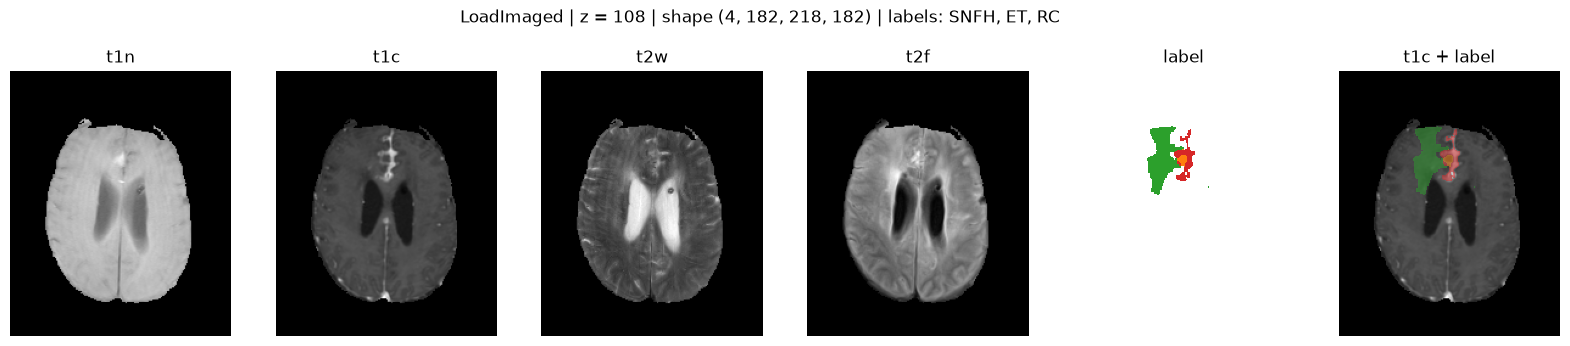

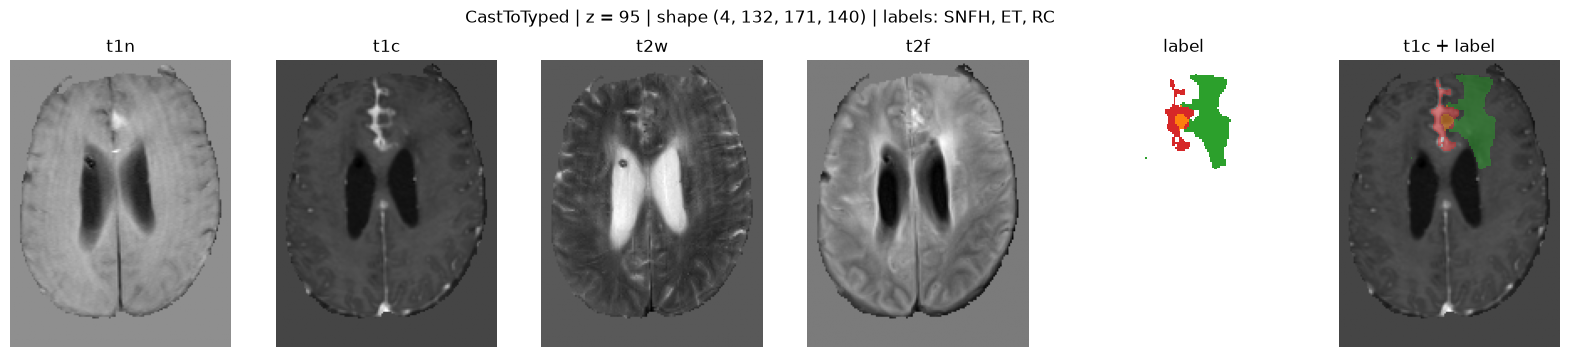

In [6]:



def axial(vol, z):
    # RAS array: axes (x, y, z); rotate so anterior is up
    return np.rot90(vol[..., z])


def show(step=-1, z=None):
    s = steps[step] if isinstance(step, int) else step
    img = s["image"].astype(np.float32)
    lab = s["label"][0] if s["label"].ndim == 4 else s["label"]
    z = best_slice(lab) if z is None else z

    fig, axes = plt.subplots(1, 6, figsize=(20, 4))

    for i, m in enumerate(MODALITIES):
        axes[i].imshow(axial(img[i], z), cmap="gray")
        axes[i].set_title(m)

    axes[4].imshow(axial(lab, z), cmap=LABEL_CMAP, vmin=0, vmax=4, interpolation="nearest")
    axes[4].set_title("label")

    axes[5].imshow(axial(img[1], z), cmap="gray")
    axes[5].imshow(axial(np.ma.masked_equal(lab, 0), z), cmap=LABEL_CMAP,
                   vmin=0, vmax=4, alpha=0.5, interpolation="nearest")
    axes[5].set_title("t1c + label")

    for ax in axes:
        ax.axis("off")
    
    present = sorted(int(v) for v in np.unique(lab) if v > 0)
    fig.suptitle(f"{s['step']} | z = {z} | shape {img.shape} | "
                 f"labels: {', '.join(LABEL_NAMES[v] for v in present)}")
    plt.show()


show(0)   # right after loading
show(-1)  # after the whole preprocessing

## 4. Evaluation pipeline: label $\rightarrow$ regions

`eval_transforms()` casts the image back to float32 and converts the single-channel label
into region channels:

| channel | definition | meaning |
|---|---|---|
| ET | label 3 | enhancing tissue |
| TC | labels 1 + 3 | tumour core |
| WT | labels 1 + 2 + 3 | whole tumour |
| RC | label 4 | resection cavity |

Regions overlap (ET $\subset$ TC $\subset$ WT), which is why this is multi-label, not multi-class.

## 5. Training transforms

Each training transform is shown on its own. Random transforms are created here with
`prob=1.0` so that the effect is always visible; in `transforms.py` they use the
probabilities from the pipeline (e.g. `prob=0.5`). All other parameters match `transforms.py`.

In [7]:
from monai.transforms import (
    CastToTyped, RandCropByPosNegLabeld, RandFlipd,
    RandScaleIntensityd, RandShiftIntensityd, SpatialPadd,
)

PATCH = (128, 128, 128)
KEYS = ["image", "label"]


LabelToRegions = next(type(t) for t in train_transforms(PATCH, 1, True).transforms
                      if not type(t).__name__.startswith(("Rand", "Load", "Cast", "Spatial")))
print("label conversion class:", LabelToRegions.__name__)


def show_pair(before, after, title, view="axial", z=None, ch=1):
    """Same slice before and after a transform (default channel: t1c)."""
    b, a = to_numpy(before["image"])[ch].astype(np.float32), to_numpy(after["image"])[ch].astype(np.float32)
    lb = to_numpy(before["label"]); lb = lb[0] if lb.shape[0] == 1 else lb[2]
    la = to_numpy(after["label"]);  la = la[0] if la.shape[0] == 1 else la[2]

    if view == "axial":
        z = best_slice(lb) if z is None else z
        cut = lambda v: np.rot90(v[:, :, z])
    else:  # coronal: fix y
        y = int((lb > 0).sum(axis=(0, 2)).argmax())
        cut = lambda v: np.rot90(v[:, y, :])

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

    for ax, img, lab, name in ((axes[0], b, lb, "before"), (axes[1], a, la, "after")):
        ax.imshow(cut(img), cmap="gray")
        ax.imshow(np.ma.masked_equal(cut(lab), 0), cmap="autumn", alpha=0.4)
        ax.set_title(f"{name}  {tuple(img.shape)}")
        ax.axis("off")
        
    fig.suptitle(f"{title} ({view} view)")
    plt.show()

label conversion class: ConvertBraTS24Labelsd


### CastToTyped $\rightarrow$ float32

Preprocessed files store images as float16 to save disk space. Before the network sees them they are
cast back to float32. Nothing changes visually; only dtype and memory.

In [8]:
s0 = dict(processed)
s1 = CastToTyped(keys="image", dtype=np.float32)(dict(s0))
for name, s in (("processed", s0), ("after cast", s1)):
    img = s["image"]
    print(f"{name:11s} dtype={img.dtype}  size={img.element_size() * img.nelement() / 1e6:.0f} MB")

processed   dtype=torch.float16  size=25 MB
after cast  dtype=torch.float32  size=51 MB


### SpatialPadd $\rightarrow$ at least patch size

After cropping to the brain, an axis can be shorter than the patch (128). Padding with zeros
makes every axis at least 128, so every random patch has exactly the same size and patches can
be stacked into a batch. Axes already longer than 128 are left unchanged.

before: (132, 171, 140) -> after: (132, 171, 140)


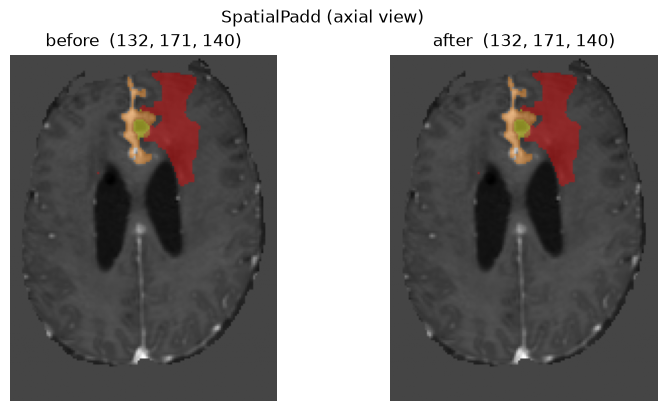

In [9]:
s2 = SpatialPadd(keys=KEYS, spatial_size=PATCH)(dict(s1))
print("before:", tuple(s1["image"].shape[1:]), "-> after:", tuple(s2["image"].shape[1:]))
show_pair(s1, s2, "SpatialPadd")

### RandCropByPosNegLabeld $\rightarrow$ where patches come from

The whole volume does not fit the network at once, so training uses $128^3$ patches.
Tumour is a small fraction of the volume, so uniformly random patches would mostly contain
no tumour. With `pos=1, neg=1` each patch centre is drawn with probability $1/2$ from tumour
voxels (label > 0) and $1/2$ from non-tumour voxels where the image is > `image_threshold`
(i.e. inside the brain, not the zero background).

To show *where* patches are taken from, an extra index volume is cropped together with the
image; its first voxel tells the patch's start position.

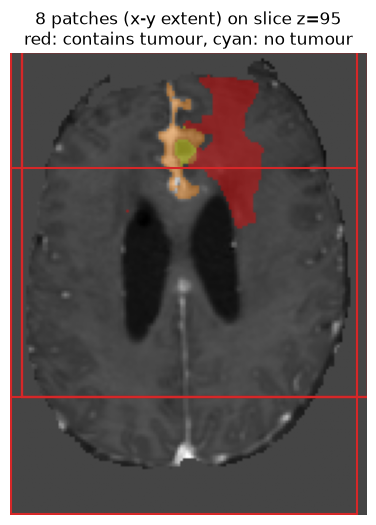

,patch,"start (x,y,z)",tumour voxels
0,0,"(4, 43, 12)",42136
1,1,"(0, 43, 12)",42136
2,2,"(4, 43, 12)",42136
3,3,"(4, 43, 12)",42136
4,4,"(0, 43, 12)",42136
5,5,"(4, 43, 12)",42136
6,6,"(4, 43, 12)",42136
7,7,"(0, 0, 0)",11372


In [10]:
H, W, D = s2["image"].shape[1:]
s2_idx = dict(s2)
s2_idx["idx"] = torch.arange(H * W * D, dtype=torch.int64).reshape(1, H, W, D)

cropper = RandCropByPosNegLabeld(
    keys=KEYS + ["idx"], label_key="label", spatial_size=PATCH,
    pos=1, neg=1, num_samples=8, image_key="image", image_threshold=0,
)
cropper.set_random_state(SEED)
crops = cropper(s2_idx)

lab_full = to_numpy(s2["label"])[0]
z = best_slice(lab_full)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(to_numpy(s2["image"])[1, :, :, z].T, cmap="gray", origin="lower")
ax.imshow(np.ma.masked_equal(lab_full[:, :, z], 0).T, cmap="autumn", alpha=0.4, origin="lower")
rows = []
for i, c in enumerate(crops):
    x0, y0, z0 = np.unravel_index(int(c["idx"][0, 0, 0, 0]), (H, W, D))
    tumour = int((to_numpy(c["label"]) > 0).sum())
    color = "tab:red" if tumour else "tab:cyan"
    ax.add_patch(plt.Rectangle((x0, y0), PATCH[0], PATCH[1], fill=False, ec=color, lw=1.5))
    rows.append({"patch": i, "start (x,y,z)": (int(x0), int(y0), int(z0)), "tumour voxels": tumour})
    
ax.set_title(f"8 patches (x-y extent) on slice z={z}\nred: contains tumour, cyan: no tumour")
ax.axis("off")
plt.show()
pd.DataFrame(rows)

### Label conversion $\rightarrow$ region channels

Same as section 4: the single-channel label (0–4) becomes ET / TC / WT / RC channels.
It is applied after cropping, so the conversion runs on a 128³ patch instead of the full volume.

In [11]:
patch = {k: v for k, v in crops[0].items() if k != "idx"}
patch_r = LabelToRegions(keys="label", include_rc=True)(dict(patch))
print("label before:", tuple(patch["label"].shape), "-> after:", tuple(patch_r["label"].shape))

label before: (1, 128, 128, 128) -> after: (4, 128, 128, 128)


### RandFlipd $\rightarrow$ mirror along one axis

Each `RandFlipd` mirrors image and label along one axis (here with prob 1). The model sees
mirrored versions of the same anatomy. Axis 0 is left–right, axis 1 anterior–posterior,
axis 2 inferior–superior (shown in a coronal view, because an axial slice cannot show it).

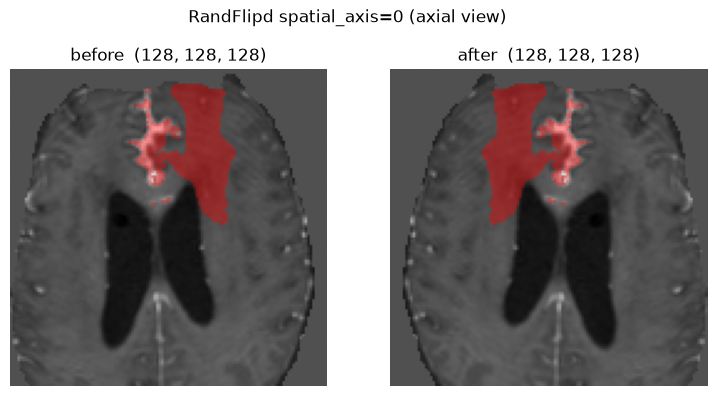

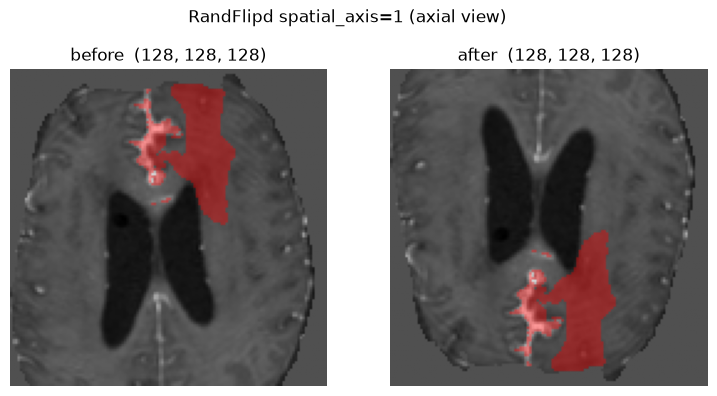

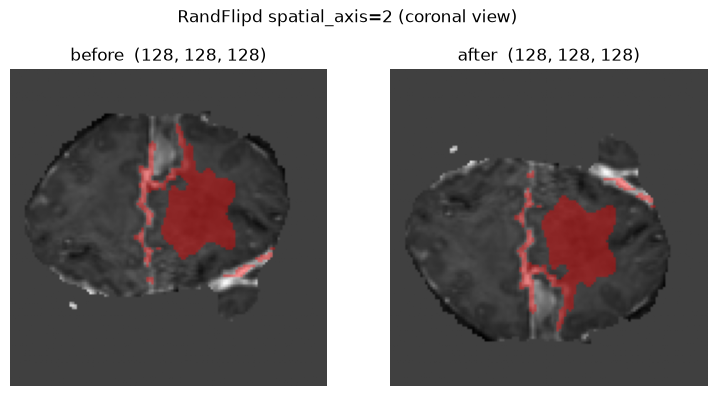

In [12]:
for axis, view in ((0, "axial"), (1, "axial"), (2, "coronal")):
    flipped = RandFlipd(keys=KEYS, prob=1.0, spatial_axis=axis)(dict(patch_r))
    show_pair(patch_r, flipped, f"RandFlipd spatial_axis={axis}", view=view)

### RandScaleIntensityd and RandShiftIntensityd → intensity changes

- `RandScaleIntensityd(factors=0.1)` multiplies the image by `1 + f`, with `f` drawn from [−0.1, 0.1].
- `RandShiftIntensityd(offsets=0.1)` adds an offset drawn from [−0.1, 0.1].

The image is already z-scored, so these are small changes relative to unit variance. The label is
not touched. Shapes of the histograms stay the same; scale stretches them, shift moves them.
Note that shift also moves the zero background by the offset.

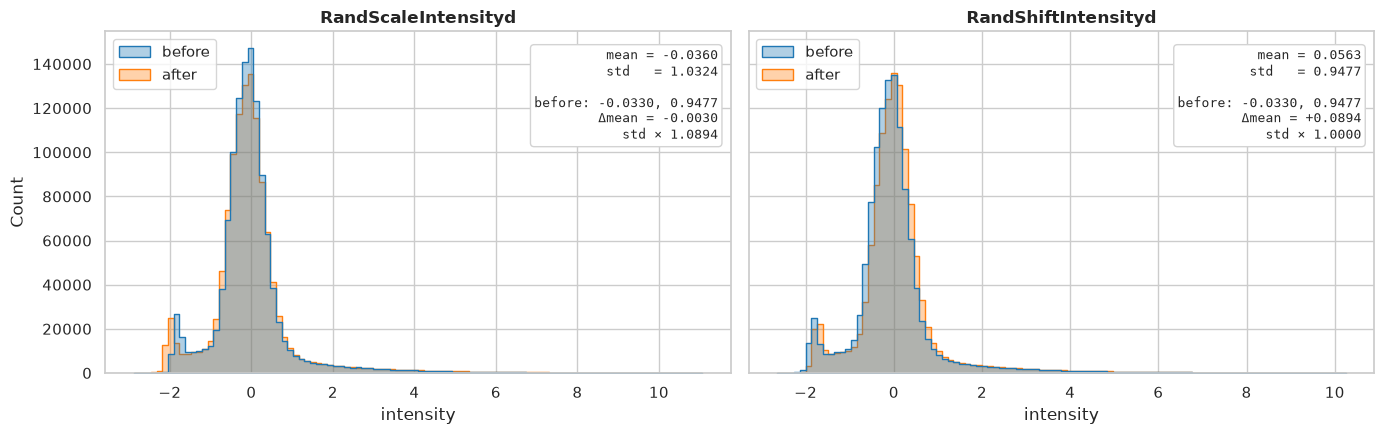

,drawn value,background after
transform,,
RandScaleIntensityd,factor × 1.0894,+0.0000
RandShiftIntensityd,offset +0.0894,+0.0894


In [13]:
sns.set_theme(style="whitegrid", context="notebook")

scale_t = RandScaleIntensityd(keys="image", factors=0.1, prob=1.0)
shift_t = RandShiftIntensityd(keys="image", offsets=0.1, prob=1.0)
scale_t.set_random_state(SEED)  # same result on every run
shift_t.set_random_state(SEED)

scaled = scale_t(dict(patch_r))
shifted = shift_t(dict(patch_r))

base = to_numpy(patch_r["image"])[1].astype(np.float64)  # t1c; float64 for exact stats
brain = base != 0


def stats(x):
    return x[brain].mean(), x[brain].std()


mean0, std0 = stats(base)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
rows = []

for ax, (name, s) in zip(axes, (("RandScaleIntensityd", scaled), ("RandShiftIntensityd", shifted))):
    new = to_numpy(s["image"])[1].astype(np.float64)
    mean1, std1 = stats(new)

    df = pd.DataFrame({
        "intensity": np.concatenate([base[brain], new[brain]]),
        "": np.repeat(["before", "after"], brain.sum()),
    })
    sns.histplot(df, x="intensity", hue="", bins=100, element="step",
                 alpha=0.35, ax=ax, palette=["tab:blue", "tab:orange"])

    ax.set_title(name, fontweight="bold")
    ax.text(0.98, 0.95,
            f"mean = {mean1:.4f}\nstd   = {std1:.4f}\n\n"
            f"before: {mean0:.4f}, {std0:.4f}\n"
            f"Δmean = {mean1 - mean0:+.4f}\nstd × {std1 / std0:.4f}",
            transform=ax.transAxes, ha="right", va="top", family="monospace", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="lightgrey"))

    rows.append({
        "transform": name,
        "drawn value": f"factor × {std1 / std0:.4f}" if "Scale" in name else f"offset {mean1 - mean0:+.4f}",
        "background after": f"{new[~brain].mean():+.4f}" if (~brain).any() else "n/a",
    })

plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).set_index("transform"))

In [14]:
PATCH = (128, 128, 128)
N_SAMPLES = 2

tr = train_transforms(PATCH, num_samples=N_SAMPLES, include_rc=True)
patches = []
for _ in range(3):  # 3 runs x N_SAMPLES patches
    patches.extend(tr(dict(processed)))

rows = []
for i, p in enumerate(patches):
    lab = to_numpy(p["label"])
    rows.append({"patch": i, "image shape": tuple(p["image"].shape),
                 **{f"{n} voxels": int(c.sum()) for n, c in zip(REGIONS, lab)}})
pd.DataFrame(rows)

,patch,image shape,ET voxels,TC voxels,WT voxels,RC voxels
0,0,"(4, 128, 128, 128)",13011,13011,39980,2156
1,1,"(4, 128, 128, 128)",5769,5769,13246,172
2,2,"(4, 128, 128, 128)",5329,5329,11361,11
3,3,"(4, 128, 128, 128)",13011,13011,39980,2156
4,4,"(4, 128, 128, 128)",13011,13011,39980,2156
5,5,"(4, 128, 128, 128)",5329,5329,11361,11


## 6. Full training pipeline: random patches

`train_transforms()` pads to the patch size, samples patches centred on tumour (`pos`)
or on brain tissue (`neg`) with ratio 1:1, converts labels and applies random flips and
intensity changes. Running it several times gives different patches.

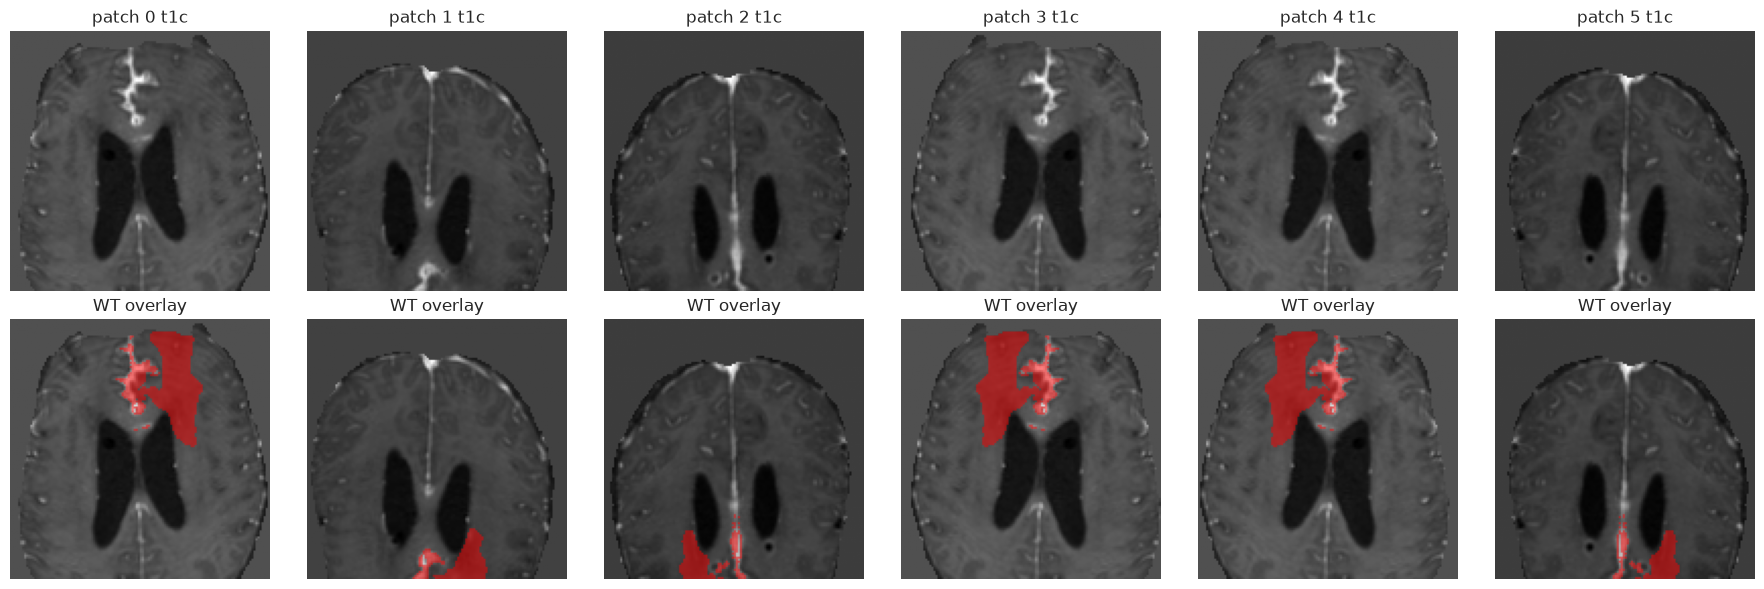

In [15]:
fig, axes = plt.subplots(2, len(patches), figsize=(3 * len(patches), 6))
for i, p in enumerate(patches):
    img, lab = to_numpy(p["image"]), to_numpy(p["label"])
    z = best_slice(lab[2])
    
    axes[0, i].imshow(axial(img[1], z), cmap="gray")
    axes[0, i].set_title(f"patch {i} t1c")

    axes[1, i].imshow(axial(img[1], z), cmap="gray")
    axes[1, i].imshow(axial(np.ma.masked_equal(lab[2], 0), z), cmap="autumn", alpha=0.5)
    axes[1, i].set_title("WT overlay")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()